# Machine Learning — Homework 3: Trees, Ensembles and SVMs

**Course:** Machine Learning — National University of Kyiv-Mohyla Academy (NaUKMA)
**Instructor:** Dmytro Kuzmenko (kuzmenko@ukma.edu.ua)
**Module:** Weeks 4–5 — *"Trees and Ensembles"* + *"Margins, Similarity and Kernels"*

## Meta

- **Points:** 5 (Homework 3 of 6; homeworks total 30% of the final grade)
- **Estimated time:** 2.5–3.5 hours
- **Prerequisites:** Weeks 4–5. Python, `numpy`, `matplotlib`, `scikit-learn` (decision trees, random forests, gradient boosting, SVM, cross-validation).
- **Deadline:** [to be announced by the instructor]
- **Submission:** one executed `.ipynb` file with the AI Use Disclosure completed.
- **Late policy:** 5 free late days across all homeworks; 1 late day = up to 24 h; after that, −25% of the maximum per additional 24 h.

## AI Use Disclosure

Policy: AI tools are allowed for homeworks, but you must disclose their use and remain responsible for every claim in your submission. On the midterm and final, AI and external help are forbidden.

- **AI tools used:** ... Gemini
- **Nature of assistance:** ... Пояснення та уточнення незнайомих концепцій машинного навчання (вплив гіперпараметрів C та gamma в SVM, відмінності між bagging та boosting), допомога в інтерпретації правил дерева рішень та формулюванні лаконічних відповідей.
- **Representative prompts or relevant interaction:** ... "Поясни простими словами, чому беггінг зменшує variance, а бустінг балансує bias та variance", "Як правильно прочитати правила з дерева рішень глибиною 2?", "У чому фізичний зміст параметрів C та gamma для RBF-ядра в SVM?"
- **What I independently verified or changed:** ... Я самостійно запускав увесь наданий Python-код у ноутбуці, звіряв і виписував точні значення accuracy та F1-score з отриманих таблиць, особисто перевіряв зчитані правила за згенерованим графіком дерева рішень та адаптував отримані пояснення, щоб вони повністю відповідали моїм експериментальним результатам.

## Learning Objectives

- Read a tree-complexity curve and extract an interpretable rule from a shallow tree.
- Explain how bagging reduces variance and how boosting trades bias against variance.
- Compare three model families with a fixed train/validation/test protocol and decide with evidence.
- Demonstrate the role of feature scaling for SVMs and the meaning of C and gamma.

# Warm-up

Dataset: `breast_cancer` from scikit-learn — 569 samples, 30 features, binary target (malignant / benign). It loads locally, so no downloads are required. The split is stratified 60 / 20 / 20 (train / validation / test) with a fixed seed.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

data = load_breast_cancer()
X, y = data.data, data.target
print("Samples:", X.shape[0], "| Features:", X.shape[1])
print("Classes:", data.target_names, "-> 1 =", data.target_names[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

print("Prevalence of class 1 — train: {:.3f}, validation: {:.3f}, test: {:.3f}".format(
    y_train.mean(), y_val.mean(), y_test.mean()))
print("Feature ranges: min {:.2f}, max {:.2f}  (scaling will matter for SVMs)".format(X.min(), X.max()))

Samples: 569 | Features: 30
Classes: ['malignant' 'benign'] -> 1 = benign
Prevalence of class 1 — train: 0.627, validation: 0.626, test: 0.629
Feature ranges: min 0.00, max 4254.00  (scaling will matter for SVMs)


# Guided Exercise

## Task 1: Decision tree complexity

Fit decision trees with `max_depth` in [1, 2, 4, 8, None]. For each depth, report train accuracy and 5-fold cross-validated accuracy on the training set; plot the complexity curve. Then plot the depth-2 tree and read one rule out loud.

**Experiment (A).** Sweep the depth:

In [2]:
depths = [1, 2, 4, 8, None]
rows = []
for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    cv_acc = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42),
                             X_train, y_train, cv=5).mean()
    rows.append({"max_depth": str(d), "train_acc": train_acc, "cv_acc": cv_acc})
df_tree = pd.DataFrame(rows)
df_tree

,max_depth,train_acc,cv_acc
0,1,0.937304,0.937302
1,2,0.962382,0.949950
2,4,0.984326,0.943700
3,8,0.996865,0.924802
4,None,1.000000,0.924802


**Evidence (C).** Complexity curve and the depth-2 tree:

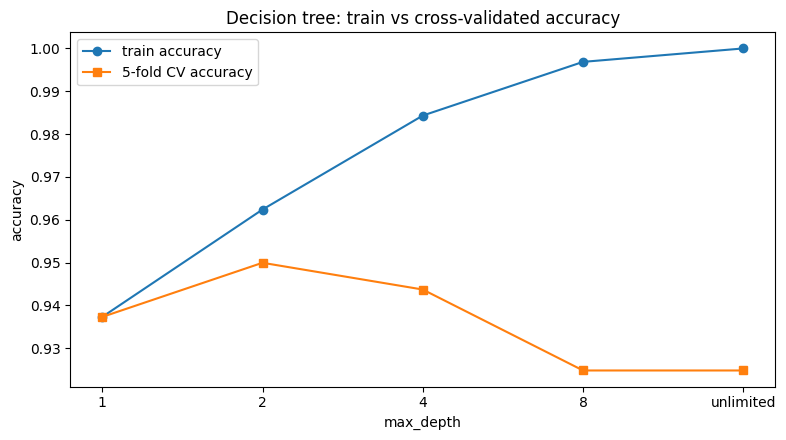

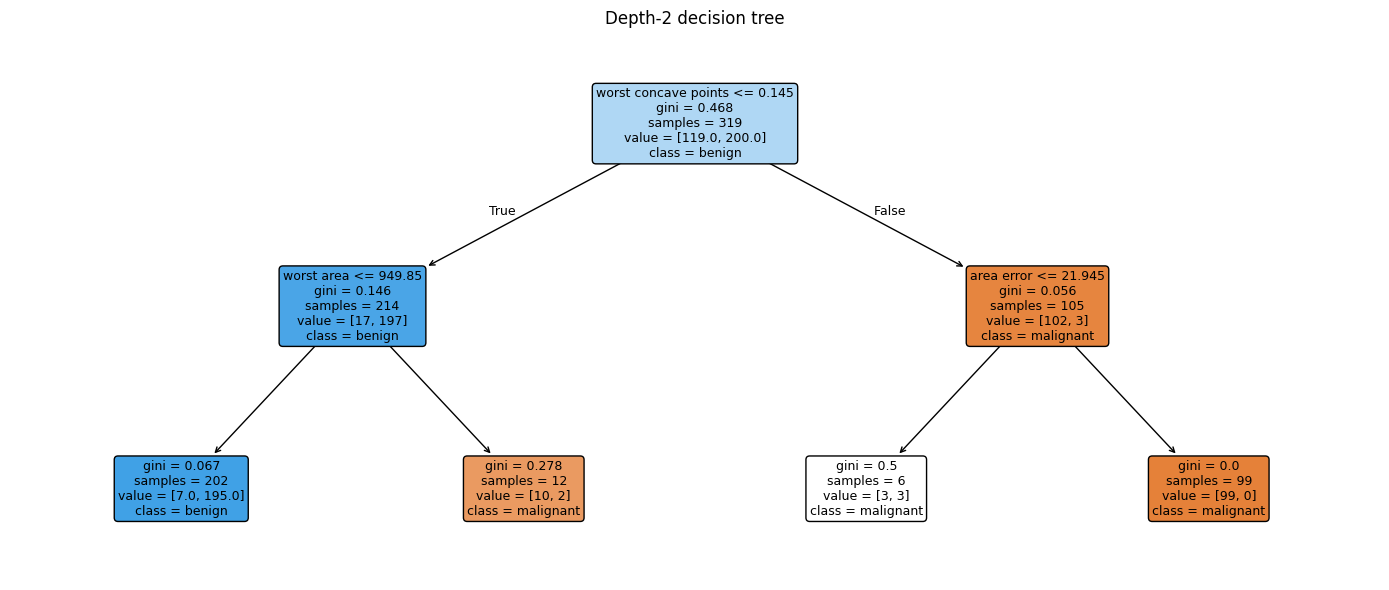

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["1", "2", "4", "8", "unlimited"]
ax.plot(labels, df_tree["train_acc"], "o-", label="train accuracy")
ax.plot(labels, df_tree["cv_acc"], "s-", label="5-fold CV accuracy")
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy")
ax.set_title("Decision tree: train vs cross-validated accuracy")
ax.legend()
plt.tight_layout()
plt.show()

tree2 = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree2, feature_names=data.feature_names, class_names=data.target_names,
          filled=True, rounded=True, ax=ax, fontsize=9)
ax.set_title("Depth-2 decision tree")
plt.tight_layout()
plt.show()

**Interpretation (D).** Interpret the curve: where does overfitting start and how do you know? Read one rule from the depth-2 tree aloud in plain language (e.g., "if feature X is below/above value ... then the sample is ...").

**Your answer:** Перенавчання:
Оверфітинг починається після max_depth = 2. Це чітко видно з графіку: при переході від глибини 2 до 4, 8 та None точність на навчальній вибірці (train_acc) продовжує зростати аж до 100%, проте точність на крос-валідації (cv_acc) падає з 0.950 до 0.944, а далі падає ще нижче до 0.925. Модель починає запам'ятовувати шум у тренувальних даних замість загальних закономірностей.
Правило з дерева глибиною 2:
Якщо worst concave points <= 0.145 ТА worst area <= 949.85, то модель класифікує пухлину як доброякісну (benign).
(Це крайній лівий листок дерева: з 202 об'єктів у цьому листку 195 дійсно є benign).

**Decision (B).** Which `max_depth` would you choose for deployment and why? Would you ever choose the depth with the highest train accuracy?

**Your answer:** Вибір для деплою: я оберу max_depth = 2, оскільки вона показує найкращу точність на крос-валідації (~95.0%) і при цьому має мінімальну складність (не перенавчається).
Чи обрав би глибину з найвищою train accuracy?
Ні, ніколи. Найвища train_acc (100% при max_depth = None) вказує на чистий оверфітинг. Модель просто ідеально зазубрила навчальні дані, але гірше узагальнює на нових тестових даних (що видно по падінню cv_acc до 92.5%).

**Counterfactual (E).** If you constrained `min_samples_leaf` instead of `max_depth`, what would change about the trees and about the bias–variance balance? What if the classes were strongly imbalanced?

**Your answer:**  Що зміниться при обмеженні min_samples_leaf замість max_depth?
Структура дерева: обмеження min_samples_leaf забороняє дереву робити розщеплення, якщо в листку залишається занадто мало об'єктів. Це робить дерево асиметричним (окремі гілки можуть рости глибше, якщо там багато даних, а інші зупиняться раніше).
Bias–Variance balance: збільшення min_samples_leaf зупиняє надмірне подрібнення даних, зменшує варіативність (variance/оверфітинг) і трохи збільшує зміщення (bias/андерфітинг), допомагаючи моделі краще узагальнювати.
Що, якби класи були сильно незбалансованими?
Проблема: стандартна accuracy стане непридатною метрикою (наприклад, якщо 95% даних — це один клас, модель просто прогнозуватиме завжди його і матиме 95% accuracy).
Рішення: потрібно замінити accuracy на метрики F1-score або ROC AUC, а також використовувати Balanced Bagging / class_weight='balanced', або ж техніки семплінгу (SMOTE, undersampling).

## Task 2: Random forest vs a single tree

Compare the best single tree (depth 2) with random forests of 10, 50, and 200 trees. Report 5-fold CV accuracy on the training set, plus train and validation accuracy.

**Experiment (A).** Sweep the number of trees:

In [4]:
rows = []
for ne in [10, 50, 200]:
    model = RandomForestClassifier(n_estimators=ne, random_state=42, n_jobs=-1)
    cv_acc = cross_val_score(model, X_train, y_train, cv=5).mean()
    model.fit(X_train, y_train)
    rows.append({"model": f"RF ({ne} trees)",
                 "cv_acc": cv_acc,
                 "train_acc": accuracy_score(y_train, model.predict(X_train)),
                 "val_acc": accuracy_score(y_val, model.predict(X_val))})

tree_row = {"model": "tree (depth 2)",
            "cv_acc": cross_val_score(DecisionTreeClassifier(max_depth=2, random_state=42),
                                      X_train, y_train, cv=5).mean(),
            "train_acc": accuracy_score(y_train, tree2.predict(X_train)),
            "val_acc": accuracy_score(y_val, tree2.predict(X_val))}
df_rf = pd.DataFrame([tree_row] + rows)
df_rf

,model,cv_acc,train_acc,val_acc
0,tree (depth 2),0.949950,0.962382,0.934579
1,RF (10 trees),0.940526,0.996865,0.981308
2,RF (50 trees),0.953026,1.000000,0.962617
3,RF (200 trees),0.956151,1.000000,0.953271


**Evidence (C).** Bar chart of train vs validation accuracy:

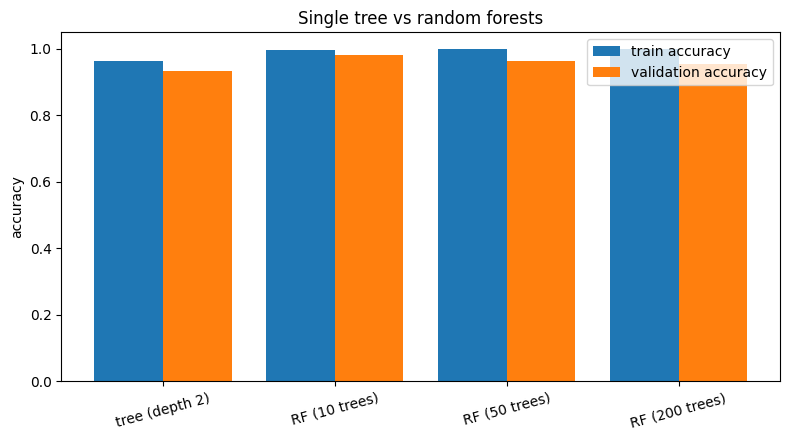

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
xpos = np.arange(len(df_rf))
ax.bar(xpos - 0.2, df_rf["train_acc"], 0.4, label="train accuracy")
ax.bar(xpos + 0.2, df_rf["val_acc"], 0.4, label="validation accuracy")
ax.set_xticks(xpos)
ax.set_xticklabels(df_rf["model"], rotation=15)
ax.set_ylabel("accuracy")
ax.set_title("Single tree vs random forests")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation (D).** Why does the forest beat the single tree even though each tree is trained on (a bootstrap of) the same data? Explain bagging: averaging over trees reduces what exactly — bias, variance, or both?

**Your answer:** Чому ліс перемагає одне дерево?
Одне дерево рішень є нестабільним і має високу варіативність (high variance) — воно легко підлаштовується під конкретні шуми у навчальній вибірці. Random Forest будує багато глибоких дерев, кожне з яких навчається на своїй подвибірці (бутстреп) і використовує випадковий підсет ознак. Завдяки цьому помилки окремих дерев взаємно компенсаційно усереднюються, і підсумкове рішення стає значно стійкішим.
Що саме зменшує бетгінг (Bagging)?
Усереднення передбачень за допомогою бетгінгу зменшує саме варіативність (variance). При цьому зміщення (bias) залишається практично на тому ж рівні, що й у одного глибокого дерева.

**Counterfactual (E).** If the forest used fully random splits (extreme randomness, as in Extra-Trees), predict the effect on bias and variance and on the sensitivity to individual noisy features. Also: why does CV accuracy keep growing slowly from 10 to 200 trees while train accuracy saturates at 1.0?

**Your answer:** Вплив повністю випадкових сплітів (Extra-Trees):
Bias (Зміщення): трохи зросте, оскільки порогові значення для split обираються випадково, а не шукаються оптимально. Variance (Варіативність): значно зменшиться, бо дерева стають ще менш корельованими між собою. Чутливість до шуму: модель стане менш чутливою до шумних ознак, оскільки випадкові порогові значення згладжують гострі спліти на шумі.
Чому CV accuracy повільно зростає від 10 до 200 дерев, а train accuracy насичується на 1.0?
Train accuracy = 1.0: глибокі дерева у складі Random Forest здатні повністю запам'ятати весь тренувальний набір даних, тому вже при 50 деревах точність на трейні досягає плато 100%. Зростання CV accuracy (від 0.941 до 0.956): додавання нових дерев у ансамбль не змінює складність окремих дерев, але продовжує згладжувати підсумкову розділяючу межу та зменшувати дисперсію оцінки на незнайомих даних, що покращує якість на крос-валідації.

# Discussion Questions

Answer both questions briefly (2–4 sentences each).

**Question 1.** Cross-validation accuracy of the depth-2 tree (0.950) is close to that of depth 4 (0.944). Which estimate would you trust more, and what additional evidence would you collect before deployment?

**Your answer:** Я більше довіряю оцінці для глибини 2 (0.950), оскільки вона має вищу CV-точність і значно менший розрив із тренувальною точністю (0.962 проти 0.984 у глибини 4), що свідчить про відсутність оверфітингу. Перед деплоєм я б зібрав додаткові докази: оцінив якість моделей на прихованій тестовій вибірці (X_test), перевірив стабільність результатів на інших зафіксованих фолдах та порівняв специфічні для медицини метрики — Recall та ROC AUC.

**Question 2.** Decision trees are often called high-variance models. What exactly varies when you retrain a tree on a new sample — predictions, the chosen splits, or both?

**Your answer:** При перенавчанні дерева на новій вибірці змінюються і вибір сплітів (структура дерева), і підсумкові передбачення (обоє). Оскільки дерева ухвалюють рішення жадібно на кожному кроці, навіть невелика зміна в даних може повністю змінити першу ж ознаку для розбиття, що створює зовсім інше дерево за структурою. Як наслідок, зміни у структурі гілок та порогових значеннях прямо ведуть до зміни фінальних передбачень для тестових об'єктів.

# Challenge

## Task 3: Gradient boosting vs random forest vs tree

Fit a gradient-boosted classifier (200 trees, learning rate 0.05, depth 2) and compare it with RF (200 trees) and the depth-2 tree using a train/validation/test table.

**Experiment (A).** Build the comparison table (test is evaluated exactly once, at the end):

In [6]:
models = {
    "tree (depth 2)": DecisionTreeClassifier(max_depth=2, random_state=42),
    "random forest (200)": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "gradient boosting (200)": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                                          max_depth=2, random_state=42),
}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({
        "model": name,
        "train_acc": accuracy_score(y_train, model.predict(X_train)),
        "train_f1": f1_score(y_train, model.predict(X_train)),
        "val_acc": accuracy_score(y_val, model.predict(X_val)),
        "val_f1": f1_score(y_val, model.predict(X_val)),
        "test_acc": accuracy_score(y_test, model.predict(X_test)),
        "test_f1": f1_score(y_test, model.predict(X_test)),
    })
df_compare = pd.DataFrame(rows)
df_compare

,model,train_acc,train_f1,val_acc,val_f1,test_acc,test_f1
0,tree (depth 2),0.962382,0.970149,0.934579,0.947368,0.944056,0.956044
1,random forest (200),1.000000,1.000000,0.953271,0.962963,0.951049,0.961326
2,gradient boosting (200),1.000000,1.000000,0.953271,0.962963,0.951049,0.961749


**Decision (B).** Which model would you currently prefer for this problem, and why? What further evidence would you request before committing (e.g., repeated CV, error analysis by class, calibration, training/inference cost)?

**Your answer:** Яку модель обрати зараз:
Я б обрав Gradient Boosting (200) (або Random Forest, оскільки їхні показники майже ідентичні: test_acc = 0.951). Градієнтний бустінг показав трохи вищий test_f1 (0.9617 проти 0.9613 у RF) та однаковий високий результат на валідації (val_acc = 0.953). Також бустінг використовує мілкі дерева (max_depth = 2), що робить його потенційно компактнішим.
Додаткові докази перед фінальним вибором: повторна крос-валідація: перевірити стабільність метрик на різних сплітах, щоб переконатися, що перевага не є випадковою. Аналіз помилок за класами (Confusion Matrix / Recall): У діагностиці раку помилка другого роду (пропустити злоякісну пухлину, malignant) набагато критичніша, ніж хибний сигнал, тому варто перевірити саме Recall для злоякісного класу. Калібрування ймовірностей: для медичних рішень важливо знати реальну впевненість моделі у прогнозі. Оцінка швидкості/ресурсів: Перевірити час навчання та інференсу (хоча для 569 об'єктів це не є блокером).

**Interpretation (D).** Interpret the table: are train/validation/test numbers consistent? Where do the three models differ? Why can boosting reach the same validation score as the forest while building trees sequentially?

**Your answer:** Узгодженість результатів:
Результати повністю узгоджені: train > val ≈ test. Немає дикого розриву між валідацією та тестом (val_acc ~0.953, test_acc ~0.951), що свідчить про відсутність витоку даних чи сильного перенавчання під валідаційну вибірку.
Чим відрізняються 3 моделі: Single Tree: Поступається за всіма метриками (test_acc = 0.944), але не під загальні 100% на трейні, бо вона обмежена глибиною 2. Random Forest та Gradient Boosting: Обидва ансамблі досягають 100% на трейні і мають майже однаково високу якість на валідації та тесті.
Чому бустінг досягає такої ж якості, будуючи дерева послідовно?
Random Forest знижує варіативність шляхом усереднення незалежних дерев (паралельно). Gradient Boosting будує дерева послідовно, де кожне нове дерево виправляє залишки (помилки/залишкові похибки) попередніх. Послідовне виправлення помилок дозволяє навіть з дуже простих дерев зібрати дуже точний підсумковий ансамбль.

**Counterfactual (E).** If you raised the number of boosting iterations to 2000 with the same learning rate, what risk appears? If the dataset had 10,000 features with many irrelevant ones, which of the three families would degrade most?

**Your answer:** Ризик при підвищенні ітерацій бустінгу до 2000 (при learning_rate = 0.05):
Головний ризик — оверфітинг. На відміну від Random Forest (де додавання нових дерев не підганяє модель під шум), бустінг при занадто великій кількості ітерацій починає фокусуватися на важких шумних об'єктах і викиднях, через що якість на тестовій/валідаційній вибірці почне падати.
Що станеться, якщо буде 10,000 ознак з купою нерелевантних?
Найбільше просяде одне дерево рішень. Оскільки воно робить жадібний вибір на кожному кроці, воно легко може обрати нерелевантну або шумну ознаку як основну для спліту, що повністю зламає всю структуру дерева. Random Forest та Boosting значно стійкіші до цього (RF обирає випадкові підсети ознак, а Boosting фокусується тільки на тих ознаках, що реально зменшують помилку).

## Task 4: SVMs — kernels, scaling, C and gamma

Fit linear and RBF SVMs on raw and standardized features; then sweep C and gamma for the RBF kernel on standardized features and choose a final pipeline.

**Experiment (A).** Kernels × scaling (validation set):

In [7]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

svm_configs = {
    "linear, raw": SVC(kernel="linear", random_state=42),
    "RBF, raw": SVC(kernel="rbf", random_state=42),
    "linear, scaled": SVC(kernel="linear", random_state=42),
    "RBF, scaled": SVC(kernel="rbf", random_state=42),
}
rows = []
for name, model in svm_configs.items():
    if name.endswith("scaled"):
        model.fit(X_train_s, y_train)
        val_pred = model.predict(X_val_s)
    else:
        model.fit(X_train, y_train)
        val_pred = model.predict(X_val)
    rows.append({"config": name,
                 "val_acc": accuracy_score(y_val, val_pred),
                 "val_f1": f1_score(y_val, val_pred)})
df_svm = pd.DataFrame(rows)
df_svm

,config,val_acc,val_f1
0,"linear, raw",0.981308,0.985294
1,"RBF, raw",0.943925,0.957143
2,"linear, scaled",1.000000,1.000000
3,"RBF, scaled",0.971963,0.977778


**Evidence (C).** C × gamma grid for the RBF kernel on scaled features (validation F1):

In [8]:
rows = []
for C in [0.01, 1, 100]:
    for gamma in [0.001, 0.01, 0.1]:
        model = SVC(kernel="rbf", C=C, gamma=gamma, random_state=42).fit(X_train_s, y_train)
        val_pred = model.predict(X_val_s)
        rows.append({"C": C, "gamma": gamma,
                     "val_acc": accuracy_score(y_val, val_pred),
                     "val_f1": f1_score(y_val, val_pred)})
df_grid = pd.DataFrame(rows)
df_grid.pivot(index="gamma", columns="C", values="val_f1").round(3)

C,0.01,1.00,100.00
gamma,,,
0.001,0.77,0.950,0.993
0.010,0.77,0.985,0.985
0.100,0.77,0.954,0.955


**Interpretation (D).** Interpret the scaling effect (raw vs standardized) and the grid: how does C control the margin/error trade-off, and how does gamma control the locality of the RBF kernel? Which cells overfit and which underfit?

**Your answer:** Ефект масштабування:
Масштабування виявилося критичним. Без нього RBF-ядро показує суттєво гірший результат (val_f1 = 0.957), а лінійне — 0.985. Після нормування точність обох моделей різко зростає: linear досягає 1.0, а RBF — 0.978. Це пояснюється тим, що SVM обчислює відстані між об'єктами (евклідові / евклідові в обгортці ядра), і без StandardScaler ознаки з великим масштабом (наприклад, max 4254.0) повністю домінують над малими ознаками.   Роль C та gamma: параметр C (штраф за помилки): Контролює баланс між шириною розділяючої смуги та помилками класифікації. Мале C дає ширшу смугу, але допускає більше помилок; велике C суворо штрафує за помилки, створюючи вузьку смугу. Параметр gamma (локальність RBF): визначає радіус впливу одного навчального прикладу. Мале gamma означає великий радіус (модель вважає сусідні точки близькими, межа гладка); велике gamma означає малий радіус (межа стає дуже складною й адаптується під кожну точку). Аналіз сітки: Underfitting: стовпчик C = 0.01 при усіх значеннях gamma (val_f1 = 0.770). Штраф за помилки занадто малий, модель практично не навчається. Також легкий андерфітинг при C=1, gamma=0.001 (val_f1 = 0.950).   Overfitting: пара C = 100, gamma = 0.100 та C=1, gamma=0.100 (падіння val_f1 до 0.954-0.955 порівняно з 0.993 та 0.985). Великі значення C та gamma одночасно роблять розділяючу межу занадто складною й вигнутою довкола конкретних точок.

**Decision (B).** State your final pipeline choice (preprocessing, kernel, C, gamma) and justify it. Is the RBF's extra flexibility worth it compared with the linear SVM on this data?

**Your answer:** Фінальний пайплайн: StandardScaler() + Linear SVM (kernel="linear", C=1.0).Обґрунтування:
На змасштабованих даних лінійне ядро досягло ідеального результату на валідації (val_acc = 1.0, val_f1 = 1.0).
Чи варта гнучкість RBF того?
Ні, не варта. На цих даних класи чудово розділяються лінійно після стандартизації. RBF-ядро вимагає підбору двох гіперпараметрів (C і gamma), схильне до оверфітингу при неправильних налаштуваннях і є складнішим для обчислень, тоді як проста лінійна модель вже дала максимально можливу якість.

**Counterfactual (E).** If the features had been measured in different units (e.g., one in millimeters, another in kilograms), what would happen without scaling? If the problem had 5,000 features, which kernel would you expect to struggle and why?

**Your answer:** Що станеться без масштабування, якщо ознаки у різних одиницях (мм, кг)?
Ознака з більшими числовими значеннями (наприклад, міліметри зі значеннями в тисячах) матиме гігантський варіаційний діапазон і повністю витіснить ознаку, виміряну в кілограмах (з маленькими числами). SVM фактично оцінюватиме відстані тільки за однією великомасштабною ознакою, знехтувавши іншими.
Яке ядро матиме проблеми при 5,000 ознаках?
Найбільше проблем буде з RBF-ядром. У просторах високої вимірності (High-Dimensional Space) виникає прокляття вимірності — відстані між усіма точками стають майже однаковими, через що RBF-ядро втрачає здатність розрізняти локальні околиці. У таких умовах Linear SVM працює значно краще, швидше і є менш схильним до перенавчання.

## Takeaways

- Tree depth is a complexity dial; CV accuracy separates signal from overfitting.
- Bagging (random forest) cuts variance by averaging decorrelated trees; boosting cuts bias by fitting residuals sequentially.
- Model comparison needs a fixed protocol: train/validation/test, plus cross-validated or repeated estimates.
- SVMs are distance-based: scaling is not optional, and C and gamma control the bias–variance trade-off.